In [22]:
from _Aplha_n_methods import Alpha_N_calc as an
from _Geometry_methods import Geometry_helper as gh
from _Prettyplt import PrettyPlot as pp

import openmc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import os
pp.makePretty(0.7)

In [23]:
#Geometry
new_geom = True
made_date = '251026'
date = "161026"
hour = 0
nr_steps = 24
timestep_units = 'h'

fuel_name = 'Fuel_CA_2'
blanket_name = 'Blanket_CA'


#Reactor geometry parameters
inner_fuel_r = 50
outer_fuel_r = 60
outer_moderater_r = 80
blanket_or = 100
    
#Control for readtor
inner_moderator_height = 75
    
materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
#materials = gh.create_materials(fuel_name)
geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                        with_blanket=True, blanket_or=blanket_or, 
                                        inner_moderator_height=inner_moderator_height, 
                                        materials=materials, fuel_name=fuel_name)

fuel = gh.get_material_by_name(fuel_name,materials)
blanket = gh.get_material_by_name(blanket_name,materials)

fuel.set_density('g/cm3',4.905)
blanket.set_density('g/cm3',4.626)

Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2


/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=1.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=2.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=5.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=3.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=4.
  warn(msg, IDWarning)


In [24]:
#Print materials
def print_dep_material(material,threshold = 1e-9):
    total = 0
    new_total = 0
    print(f'\n{material.name}')
    print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        new_total += nuc_percent
        if nuc_percent > threshold:
            print(f'{nuc_name}\t {nuc_percent:.3g}')
    print(f'total: {total:.5g}')
    print(f'new_total: {new_total:.5g}')
def check_fuel_from_ORNL(fuel,threshold = 1e-7):
    print('\n',fuel.name)
    nuclide_lib = {}
    total = 0
    for nuc,dens in fuel.get_nuclide_densities().items():
        symbol,Z,A = an.isolate_atomic_symbol(nuc)
        if symbol != 'F':
            #print(nuc,dens)
            mol = dens.percent
            total += mol
            if symbol in nuclide_lib:
                nuclide_lib[symbol]+=mol
            else:
                nuclide_lib[symbol]=mol
    
    for nuc in nuclide_lib:
        if nuclide_lib[nuc]/total*100 > threshold and nuc != 'F':
            print(f'{nuc}: {nuclide_lib[nuc]/total*100:.10g}')

print_dep_material(fuel)
print_dep_material(blanket)

check_fuel_from_ORNL(fuel)
check_fuel_from_ORNL(blanket)



Fuel_CA_2
density: 4.905
F19	 0.644
Li6	 2.6e-06
Li7	 0.26
U234	 4.3e-05
U235	 0.00481
U236	 2.21e-05
U238	 0.0912
total: 0.08001
new_total: 1

Blanket_CA
density: 4.626
F19	 0.655
Li6	 1.79e-05
Li7	 0.241
Th230	 2.07e-05
Th232	 0.103
total: 0.073034
new_total: 1

 Fuel_CA_2
Li: 72.99999995
Mo: 1.451180995e-07
Np: 1.985725295e-07
U: 26.99999897
Zr: 1.21836728e-07

 Blanket_CA
Li: 70
Th: 29.99999993


/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=10.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=11.
  warn(msg, IDWarning)


4.905
volume mass: 1.87e+06 g
amout change in Pu241 5.063e-17 = 9.465e-11 g
amout change in Pu239 1.039e-08 = 0.01943 g
amout change in U233 2.812e-14 = 5.257e-08 g
0.01943334863623616


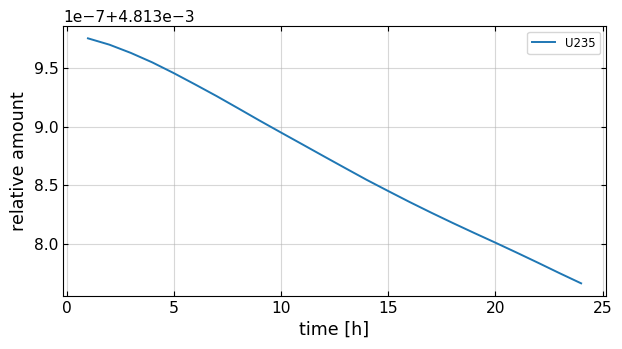

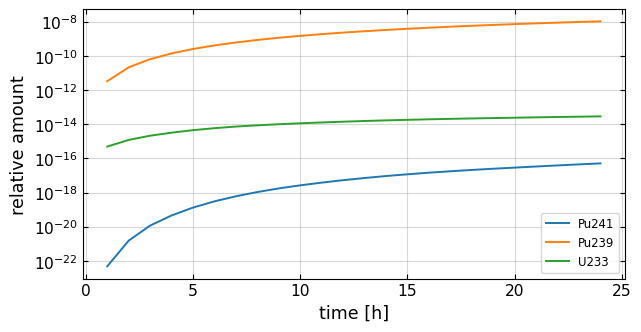

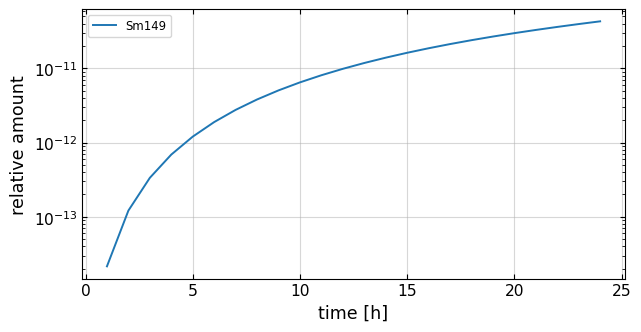

In [38]:
def check_isotopes_from_dep(material,isotopes):
    total = 0
    new_total = 0
    nuclide_lib = {}
    #print(f'\n{material.name}')
    #print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        if nuc_name in isotopes:
            nuclide_lib[nuc_name]=nuc_percent
            #print(f'{nuc_name}: {nuclide_lib[nuc_name]*100:.10g}')
    #print(total)
    return nuclide_lib
def get_isotopes_over_time(isotopes,material_name,fuel_name):
    isotopes_over_time = {}
    for isotope in isotopes:
        isotopes_over_time[isotope] = np.zeros(nr_steps)
        for hour in range(nr_steps):
            mats = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
            mat = gh.get_material_by_name(material_name,mats)
            
            isotope_lib = check_isotopes_from_dep(mat,isotope)
            
            isotopes_over_time[isotope][hour]= isotope_lib[isotope]
        

    return isotopes_over_time

#check_isotopes_from_dep(fuel,['Xe135','U235'])
fuel_U = ['U235']
breeding_fuel = ['Pu241','Pu239','U233']
poisons =['Sm149'] #['Xe135','I135','Sm149']
total_fissile_mass = 0
for isotopes,name in zip([fuel_U,breeding_fuel,poisons],['fuel_U','breeding_fuel','poisons']):


    isotopes_over_time = get_isotopes_over_time(isotopes,fuel_name,fuel_name)
    
    fig,ax = plt.subplots()
    ax
    for isotope in isotopes:
        ax.plot(np.array(range(nr_steps))+1,isotopes_over_time[isotope],label = isotope)
    ax.set_xlabel('time [h]')
    ax.set_ylabel('relative amount')
    if name != 'fuel_U':
        ax.semilogy()
    ax.legend()
    ax.grid(alpha=0.5)
    if name == 'breeding_fuel':
        print(fuel.density)
        fuel_mass = fuel.volume*fuel.density
        print(f'volume mass: {fuel_mass:.4g} g')
        for isotope in isotopes:
            concentration = isotopes_over_time[isotope][nr_steps-1]-isotopes_over_time[isotope][0]
            total_fissile_mass += concentration*fuel_mass
            print(f'amout change in {isotope} {concentration:.4g} = {concentration*fuel_mass:.4g} g')
    
    #pp.savefig(f'{made_date}/{name}_{date}')
print(total_fissile_mass)

/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=10.
  warn(msg, IDWarning)
/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=11.
  warn(msg, IDWarning)


4.626
volume mass: 9.456e+06 g
amout change in U233 2.939e-10 = 0.002779 g
amout change in U235 6.098e-20 = 5.767e-13 g
0.022212583369981144


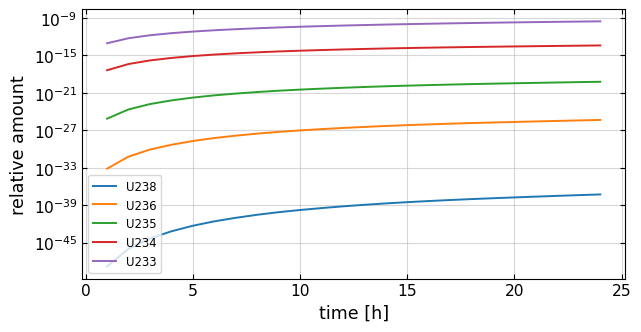

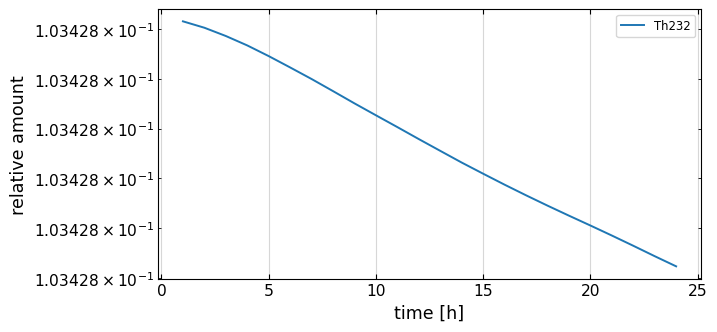

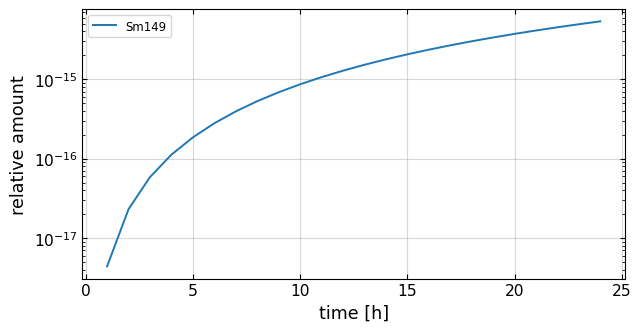

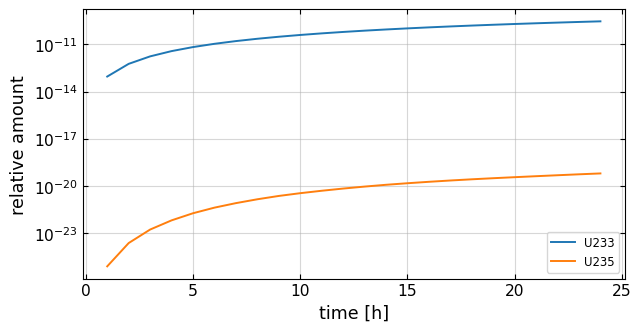

In [39]:
blanket_U = ['U238','U236','U235','U234','U233']
blanket_Th = ['Th232']
breeding_blanket = ['U233','U235']

for isotopes,name in zip([blanket_U,blanket_Th,poisons,breeding_blanket],['blanket_U','blanket_Th','poisons','breeding_blanket']):


    isotopes_over_time = get_isotopes_over_time(isotopes,'Blanket_CA',fuel_name)
    
    fig,ax = plt.subplots()
    ax
    for isotope in isotopes:
        ax.plot(np.array(range(nr_steps))+1,isotopes_over_time[isotope],label = isotope)
    ax.set_xlabel('time [h]')
    ax.set_ylabel('relative amount')
    ax.semilogy()
    ax.legend()
    ax.grid(alpha=0.5)
    if name == 'breeding_blanket':
        print(blanket.density)
        blanket_mass = blanket.volume*blanket.density
        print(f'volume mass: {blanket_mass:.4g} g')
        for isotope in isotopes:
            concentration = isotopes_over_time[isotope][nr_steps-1]-isotopes_over_time[isotope][0]
            total_fissile_mass += concentration*blanket_mass
            print(f'amout change in {isotope} {concentration:.4g} = {concentration*blanket_mass:.4g} g')
    
    pp.savefig(f'{made_date}/{name}_{date}')
print(total_fissile_mass)



 Fuel_CA_2
Writing SRIM file after 25 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71


/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=1.
  warn(msg, IDWarning)


Getting cross sections...
Making kernels and integrent...
setup done in 24.042016153980512 s
total_n_per_s: 3.546e+05 for Fuel_CA_2


 Blanket_CA
Writing SRIM file after 19 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71
Getting cross sections...
Making kernels and integrent...
setup done in 25.56805634999182 s
total_n_per_s: 4.0498e+05 for Blanket_CA


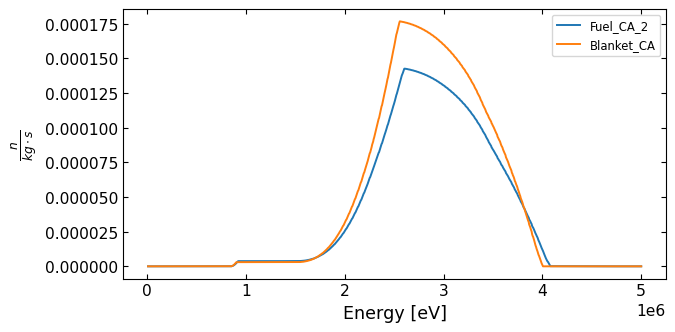

In [7]:
#Alpha-n from material
def shell_vol_calc(geom_or,geom_ir):
    volume=4/3*np.pi*(geom_or**3-geom_ir**3)
    return volume

def set_source(material,innr_r,outer_r):
    print(f'\n\n {material.name}')
    n_intensities,n_energies,n_per_s_per_kg = an.neutron_spectra_from_material(material,E_min=1e4,
                                                                               nr_points=1000,nr_energies=1000,
                                                                               new_file=True)
    
    n_intensities = np.clip(n_intensities,0,None)
    energy = openmc.stats.Tabular(n_energies, n_intensities)
    
    ax.plot(n_energies,n_intensities,label=material.name)
    
    material_vol = shell_vol_calc(outer_fuel_r,inner_fuel_r)
    material_mass = material.density*material_vol/1000
    total_n_per_s = n_per_s_per_kg*material_mass

    print(f'total_n_per_s: {total_n_per_s:.5g} for {material.name}')

    return openmc.IndependentSource(space=fuel_space, energy=energy,particle='neutron', strength=total_n_per_s)

inner_fuel_radius = geom.get_surfaces_by_name('fuel_inner')[0].bounding_box('-')[1][0]
outer_fuel_radius = geom.get_surfaces_by_name('fuel_outer')[0].bounding_box('-')[1][0]

inner_blanket_radius = geom.get_surfaces_by_name('blanket_inner')[0].bounding_box('-')[1][0]
outer_blanket_radius = geom.get_surfaces_by_name('blanket_outer')[0].bounding_box('-')[1][0]

fuel_space = openmc.stats.spherical_uniform(r_outer=outer_fuel_radius,r_inner=inner_fuel_radius)
blanket_space = openmc.stats.spherical_uniform(r_outer=outer_blanket_radius,r_inner=inner_blanket_radius)

fig,ax =plt.subplots()

ax.set_xlabel('Energy [eV]')
ax.set_ylabel(r'$\frac{n}{kg\cdot s}$')

hour = 20

materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
fuel = gh.get_material_by_name(fuel_name,materials)
blanket = gh.get_material_by_name(blanket_name,materials)
fuel.set_density('g/cm3',4.905)
blanket.set_density('g/cm3',4.626)

fuel_src = set_source(fuel,inner_fuel_radius,outer_fuel_radius)
blanket_src = set_source(blanket,inner_blanket_radius,outer_blanket_radius)


ax.legend()






In [8]:
#Settings
settings = openmc.Settings()
settings.run_mode = 'eigenvalue'
settings.source =  [fuel_src,blanket_src]   # evt. + SF-kilde som separat source
settings.batches = 150
settings.inactive = 20
settings.particles = 10000 

#Fixing Li6 at 900 K doesn't have a cross section 
settings.temperature = {
    'method': 'nearest',
    'tolerance': 1000}

model_eigen = openmc.Model(geometry=geom, materials=materials, settings=settings)



In [9]:
#Finding k_eff
#model_eigen.run()

In [10]:
keffs = np.zeros(nr_steps)
keffs_std = np.zeros(nr_steps)
for step in range(nr_steps):
    openmc.reset_auto_ids()
    os.system('rm s*h5')
    os.system('rm p*h5')
    os.system("rm model.xml")
    os.system("rm summary.h5")
    materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{step}_h.xml')
    #materials = gh.create_materials(fuel_name)
    geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                            with_blanket=True, blanket_or=blanket_or, 
                                            inner_moderator_height=inner_moderator_height, 
                                            materials=materials, fuel_name=fuel_name)
    
    fuel = gh.get_material_by_name(fuel_name,materials)
    blanket = gh.get_material_by_name(blanket_name,materials)
    
    model_eigen.geometry = geom
    model_eigen.materials = materials
    model_eigen.run()
    with openmc.StatePoint(f'statepoint.{settings.batches}.h5') as sp:
        keff = sp.keff
    
    keffs[step] = keff.nominal_value
    keffs_std[step] = keff.std_dev
    
    os.system(f'statepoint.{settings.batches}.h5')
    print(keffs[step])

#Saving results
data_to_file = np.column_stack((keffs,keffs_std))
np.savetxt(f'data/eigenvalue_{date}_time_{nr_steps}_{timestep_units}.csv',data_to_file,delimiter=",",
           header='keffs,keffs_std')

Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2


rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9820035644238686
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

...

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9808205791607247
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9796689911044976
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.150.h5: not found


In [11]:
print(keffs)

[0.98200356 0.98475212 0.9825945  0.98429381 0.98227866 0.98158534
 0.98311537 0.98260161 0.98200088 0.98081441 0.98161836 0.98093942
 0.98237226 0.98041537 0.98162329 0.98127102 0.98096998 0.98161146
 0.98027186 0.9799798  0.97965477 0.98082058 0.97966899 0.98081623]


In [12]:
#Geometry
new_geom = True
made_date = '281026'
date = "181026"
hour = 0
nr_steps = 80
timestep_units = 'h'

#Reactor geometry parameters
inner_fuel_r = 50
outer_fuel_r = 60
outer_moderater_r = 80
blanket_or = 100
    
#Control for readtor
inner_moderator_height = 80
    

In [13]:
keffs = np.zeros(nr_steps)
keffs_std = np.zeros(nr_steps)
for step in range(nr_steps):
    openmc.reset_auto_ids()
    os.system('rm s*h5')
    os.system('rm p*h5')
    os.system("rm model.xml")
    os.system("rm summary.h5")
    materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{step}_h.xml')
    #materials = gh.create_materials(fuel_name)
    geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                            with_blanket=True, blanket_or=blanket_or, 
                                            inner_moderator_height=inner_moderator_height, 
                                            materials=materials, fuel_name=fuel_name)
    
    fuel = gh.get_material_by_name(fuel_name,materials)
    blanket = gh.get_material_by_name(blanket_name,materials)
    
    model_eigen.geometry = geom
    model_eigen.materials = materials
    model_eigen.run()
    with openmc.StatePoint(f'statepoint.{settings.batches}.h5') as sp:
        keff = sp.keff
    
    keffs[step] = keff.nominal_value
    keffs_std[step] = keff.std_dev
    
    os.system(f'statepoint.{settings.batches}.h5')
    print(keffs[step])

#Saving results
data_to_file = np.column_stack((keffs,keffs_std))
np.savetxt(f'data/eigenvalue_{date}_time_{nr_steps}_{timestep_units}.csv',data_to_file,delimiter=",",
           header='keffs,keffs_std')

rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9980298815092004
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


...

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9780098625147621
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.150.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9807301376443645
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.150.h5: not found


In [14]:
print(keffs)

[0.99802988 0.99740407 0.99701972 0.99504116 0.99188816 0.99004903
 0.98841153 0.98514422 0.98167784 0.97694929 0.96333775 0.93815719
 0.90471327 0.8692957  0.84103586 0.82228406 0.80787888 0.79737356
 0.79092075 0.78457139 0.7817291  0.78038223 0.7799107  0.78281832
 0.78305246 0.78630979 0.78998388 0.79418878 0.79870717 0.80360466
 0.80758374 0.81318614 0.81906887 0.82431597 0.82980262 0.83591147
 0.84399905 0.84743794 0.85515737 0.86058636 0.86627363 0.87102029
 0.87613001 0.88245565 0.88869203 0.89233716 0.89953971 0.90375184
 0.90905471 0.91390451 0.91830991 0.921476   0.92655623 0.93120332
 0.93393383 0.93752316 0.94149283 0.94270907 0.94853634 0.95082311
 0.95269308 0.95406489 0.95762067 0.9590706  0.96066978 0.96322752
 0.96525338 0.9672193  0.96945215 0.97064375 0.97191992 0.97303876
 0.97324926 0.97575473 0.9764963  0.97894787 0.98005035 0.97800986
 0.98073014 0.9808438 ]
